# Step 1: Graph construction
One graph per document, built from your three existing outputs: InLegalBERT embeddings, NER JSON, and the Step 0 oracle labels.

**Nodes** = sentences. **Edges** (3 relation types, all bidirectional): `0` shared entity, `1` semantic similarity (kNN), `2` sequential neighbours.

Each graph is saved as a plain `dict` of tensors (`graphs/<split>/<doc_id>.pt`), not a pickled PyG object, so it loads with `weights_only=True` on any PyTorch version. Conversion to a PyG `Data` object is one function call (last cell).

Edit the paths in cell 2 (copy the same values you used in Step 0).

In [6]:
!pip -q install rapidfuzz tqdm
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
import os, re, json, math, time, warnings
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import torch
from tqdm.auto import tqdm

# ============ EDIT THESE (same values as Step 0) ============
BASE      = "/content/drive/MyDrive/inabs_project"
NER_DIR   = f"{BASE}/ner"            # <split>/<doc_id>.json
EMB_DIR   = f"{BASE}/embeddings"     # <split>/<doc_id>.pt   (searched recursively if layout differs)
LABEL_DIR = f"{BASE}/labels"         # output of Step 0
GRAPH_DIR = f"{BASE}/graphs"         # output of this step
SPLIT_NAMES = ["train", "validate", "test"]
# =============================================================

CFG = dict(
    emb_dim=768,
    # entity edges
    ent_min_score=0.80,      # drop low-confidence NER spans
    ent_min_chars=3,         # drop tiny strings
    ent_fuzzy_threshold=90,  # merge near-duplicate entity strings (rapidfuzz token_sort_ratio)
    ent_min_df=2,            # entity must occur in >= 2 sentences to create an edge
    ent_max_df_frac=0.15,    # drop entities in more than 15% of sentences ("Supreme Court") ...
    ent_max_df_abs=40,       # ... or in more than 40 sentences (limits clique size)
    # semantic edges (cosine on mean-centred embeddings, top-k per node)
    sem_k=6,
    sem_min_gap=2,           # ignore neighbours closer than this (sequential edges already cover them)
    sem_min_sim=0.0,
    # sequential edges
    seq_window=1,            # 1 = i<->i+1 ; 2 also adds i<->i+2 with weight 0.5
)
OVERWRITE = False   # False = skip finished docs (resume-safe). A changed CFG triggers a rebuild automatically.
RELATIONS = ["entity", "semantic", "sequential"]

## 1. Helpers: entity normalisation and near-duplicate merging

In [8]:
try:
    from rapidfuzz import process as rf_process, fuzz as rf_fuzz
    HAS_RF = True
except ImportError:
    HAS_RF = False
    print("rapidfuzz not found: near-duplicate entity merging disabled (exact matches only)")

def norm_entity(t):
    """'Mair & Co.', 'Mair & Co' and 'Mair and Co' -> 'mair and co'"""
    t = str(t).lower().replace("&", " and ")
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]|_", " ", t)).strip()

def _digits(s): return re.findall(r"\d+", s)

def cluster_entities(counts, thr):
    """Merge near-duplicate strings ('fazal ali' ~ 'fazal ali j'). Strings whose numbers differ
    ('section 34' vs 'section 35') are never merged. Returns {string: canonical string}."""
    names = list(counts)
    mapping = {s: s for s in names}
    m = len(names)
    if not HAS_RF or m < 2 or m > 4000:
        return mapping
    sim = rf_process.cdist(names, names, scorer=rf_fuzz.token_sort_ratio, score_cutoff=thr)
    ii, jj = np.nonzero(np.triu(sim >= thr, k=1))
    parent = list(range(m))
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]; a = parent[a]
        return a
    for i, j in zip(ii, jj):
        if _digits(names[i]) == _digits(names[j]):
            ri, rj = find(i), find(j)
            if ri != rj: parent[rj] = ri
    groups = defaultdict(list)
    for i in range(m): groups[find(i)].append(names[i])
    for members in groups.values():
        canon = max(members, key=lambda s: (counts[s], -len(s)))
        for s in members: mapping[s] = canon
    return mapping

## 2. Graph builder (one document -> one graph)

In [9]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

def _py(v):
    """numpy scalar -> plain python (keeps torch.load(weights_only=True) happy)"""
    return v.item() if hasattr(v, "item") else v

def n_components(n, pairs):
    if n == 0: return 0
    if not pairs: return n
    a = np.array([p[0] for p in pairs]); b = np.array([p[1] for p in pairs])
    g = coo_matrix((np.ones(len(a)), (a, b)), shape=(n, n))
    return int(connected_components(g, directed=False)[0])

def build_doc_graph(doc_id, split, emb, ner, lab, V, C):
    sents = sorted(ner["sentences"], key=lambda s: s["sent_id"])
    n = len(sents)
    if n < 2:                                  raise ValueError(f"only {n} sentence(s)")
    if emb.ndim != 2 or emb.shape[0] != n:     raise ValueError(f"embedding shape {tuple(emb.shape)} != {n} sentences")
    if emb.shape[1] != C["emb_dim"]:           raise ValueError(f"embedding dim {emb.shape[1]} != {C['emb_dim']}")
    if len(lab["y"]) != n:                     raise ValueError(f"label length {len(lab['y'])} != {n} sentences")

    emb = emb.astype(np.float32)
    n_bad = int((~np.isfinite(emb)).sum())
    if n_bad: emb = np.nan_to_num(emb, nan=0.0, posinf=0.0, neginf=0.0)
    texts = [s["text"] for s in sents]

    # ---------------- entities ----------------
    raw = []                                                    # per sentence: [(normalised text, label)]
    for s in sents:
        items = []
        for e in s.get("entities", []) or []:
            if float(e.get("score", 1.0)) < C["ent_min_score"]: continue
            t = norm_entity(e.get("text", ""))
            if len(t) < C["ent_min_chars"]: continue
            items.append((t, str(e.get("label", "UNK"))))
        raw.append(items)
    counts = Counter(t for items in raw for t, _ in items)
    mapping = cluster_entities(counts, C["ent_fuzzy_threshold"])
    inv = defaultdict(set)
    for i, items in enumerate(raw):
        for t, _ in items: inv[mapping[t]].add(i)

    max_df = min(max(5, int(C["ent_max_df_frac"] * n)), C["ent_max_df_abs"])
    ent_w, kept = defaultdict(float), set()
    for ent, ids in inv.items():
        df = len(ids)
        if df < C["ent_min_df"] or df > max_df: continue
        w = math.log(n / df)
        if w <= 0: continue
        kept.add(ent); ids = sorted(ids)
        for a in range(df):
            for b in range(a + 1, df):
                ent_w[(ids[a], ids[b])] += w
    if ent_w:                                                   # scale to (0, 1]
        mx = max(ent_w.values()); ent_w = {k: v / mx for k, v in ent_w.items()}
    sent_entities = [sorted({mapping[t] for t, _ in items} & kept) for items in raw]

    # ---------------- semantic edges ----------------
    X = emb - emb.mean(0, keepdims=True)                        # embeddings are anisotropic: centre first
    X = X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-8)
    sim = X @ X.T
    idx = np.arange(n)
    sim[np.abs(idx[:, None] - idx[None, :]) < C["sem_min_gap"]] = -np.inf   # also removes the diagonal
    k = min(C["sem_k"], n - 1)
    sem_w = {}
    top = np.argpartition(-sim, kth=k - 1, axis=1)[:, :k]
    for i in range(n):
        for j in top[i]:
            if sim[i, j] > C["sem_min_sim"]:
                sem_w[(min(i, int(j)), max(i, int(j)))] = float(sim[i, j])

    # ---------------- sequential edges ----------------
    seq_w = {}
    for d in range(1, C["seq_window"] + 1):
        for i in range(n - d): seq_w[(i, i + d)] = 1.0 / d

    # ---------------- assemble (both directions) ----------------
    src, dst, et, ew, n_und = [], [], [], [], []
    for r, d in enumerate([ent_w, sem_w, seq_w]):
        n_und.append(len(d))
        for (a, b), w in d.items():
            src += [a, b]; dst += [b, a]; et += [r, r]; ew += [w, w]
    edge_index = np.array([src, dst], dtype=np.int64)
    edge_type, edge_weight = np.array(et, dtype=np.int64), np.array(ew, dtype=np.float32)

    # ---------------- node features ----------------
    pos = idx / (n - 1)
    nwords = np.array([len(t.split()) for t in texts])
    secs = [(s.get("section") or "OTHER") for s in sents]
    sec_oh = np.zeros((n, len(V["sections"])), np.float32)
    for i, sname in enumerate(secs):
        sec_oh[i, V["sections"].index(sname if sname in V["sections"] else "OTHER")] = 1.0
    lab_cnt = np.zeros((n, len(V["labels"])), np.float32)
    for i, items in enumerate(raw):
        for _, l in items:
            if l in V["labels"]: lab_cnt[i, V["labels"].index(l)] += 1
    extra = np.concatenate([pos[:, None], (np.log1p(nwords) / 6.0)[:, None],
                            (np.log1p([len(r) for r in raw]) / 3.0)[:, None],
                            sec_oh, np.log1p(lab_cnt) / 2.0], axis=1).astype(np.float32)
    feat_names = (["rel_position", "log_words", "log_n_entities"]
                  + [f"section_{s}" for s in V["sections"]] + [f"ent_{l}" for l in V["labels"]])
    x = np.concatenate([emb, extra], axis=1)

    # ---------------- stats ----------------
    deg_ent = np.zeros(n)
    for a, b in ent_w: deg_ent[a] += 1; deg_ent[b] += 1
    all_pairs = list(ent_w) + list(sem_w) + list(seq_w)
    y = np.array(lab["y"], dtype=np.float32)
    stats = dict(
        num_nodes=n, edges_entity=n_und[0], edges_semantic=n_und[1], edges_sequential=n_und[2],
        directed_edges=int(edge_index.shape[1]), entities_raw=len(counts), entities_kept=len(kept),
        frac_nodes_no_entity_edge=float((deg_ent == 0).mean()),
        components_full=n_components(n, all_pairs), components_entity_only=n_components(n, list(ent_w)),
        positives=int(y.sum()), pos_rate=float(y.mean()), nonfinite_emb=n_bad,
    )
    stats = {kk: _py(vv) for kk, vv in stats.items()}

    return dict(
        doc_id=doc_id, split=split, filename=ner.get("filename", doc_id), num_nodes=n, version=1,
        x=torch.from_numpy(x), emb_dim=int(C["emb_dim"]), feat_names=feat_names,
        edge_index=torch.from_numpy(edge_index), edge_type=torch.from_numpy(edge_type),
        edge_weight=torch.from_numpy(edge_weight), relation_names=list(RELATIONS),
        y=torch.from_numpy(y), y_soft=torch.tensor(lab["soft"], dtype=torch.float32),
        oracle_idx=[int(i) for i in lab["selected_idx"]],
        sentences=texts, sections=secs, sent_words=torch.from_numpy(nwords.astype(np.int64)),
        sent_entities=sent_entities, reference=lab.get("reference", ""), stats=stats,
    )

## 3. Collect the documents (exactly the 460 from Step 0) and build vocabularies

In [10]:
# --- which docs: Step 0's manifest (falls back to the label folders)
mf = Path(LABEL_DIR, "splits.json")
if mf.exists():
    manifest = {s: list(v) for s, v in json.load(open(mf)).items() if s in SPLIT_NAMES}
else:
    manifest = {s: sorted(p.stem for p in Path(LABEL_DIR, s).glob("*.json")) for s in SPLIT_NAMES}
print({s: len(v) for s, v in manifest.items()}, "documents to graph")

# --- locate embedding files (by split folder + file name, with a recursive fallback)
emb_by_split, emb_any = {}, {}
for p in Path(EMB_DIR).rglob("*.pt"):
    rel = p.relative_to(EMB_DIR)
    emb_by_split[(rel.parts[0].lower() if len(rel.parts) > 1 else "", p.stem)] = p
    emb_any[p.stem] = p
print(f"found {len(emb_any)} embedding files")

def find_emb(split, doc_id):
    return emb_by_split.get((split.lower(), doc_id)) or emb_any.get(doc_id)

# --- config / vocab handling (resume-safe, rebuilds if CFG changed)
Path(GRAPH_DIR).mkdir(parents=True, exist_ok=True)
cfg_path = Path(GRAPH_DIR, "graph_config.json")
saved = json.load(open(cfg_path)) if cfg_path.exists() else None
rebuild = OVERWRITE or saved is None or saved.get("cfg") != CFG or saved.get("relations") != RELATIONS
if saved is not None and not OVERWRITE and rebuild:
    print("CFG changed since the last run -> rebuilding all graphs")

if rebuild:
    sec_c, lab_c = Counter(), Counter()
    for split in ([s for s in ["train"] if s in manifest] or SPLIT_NAMES):   # vocab from train docs only
        for doc_id in manifest[split]:
            f = Path(NER_DIR, split, doc_id + ".json")
            if not f.exists(): continue
            for s in json.load(open(f, encoding="utf-8"))["sentences"]:
                sec_c[s.get("section") or "OTHER"] += 1
                for e in s.get("entities", []) or []: lab_c[str(e.get("label", "UNK"))] += 1
    VOCAB = dict(sections=sorted(set(sec_c) | {"OTHER"}), labels=sorted(lab_c))
else:
    VOCAB = saved["vocab"]
print("sections:", VOCAB["sections"]); print("entity labels:", VOCAB["labels"])

{'train': 300, 'validate': 60, 'test': 100} documents to graph
found 460 embedding files
sections: ['ARGUMENTS', 'FACTS', 'ISSUES', 'JUDGMENT', 'OTHER', 'PREAMBLE', 'REASONING', 'STATUTES']
entity labels: ['CASE_NUMBER', 'CITATION', 'COURT', 'DATE', 'GPE', 'JUDGE', 'LAWYER', 'ORG', 'OTHER_PERSON', 'PETITIONER', 'PRECEDENT', 'PROVISION', 'RESPONDENT', 'STATUTE', 'WITNESS']


## 4. Build all graphs (resumable; a bad document is logged and skipped, never crashes the run)

In [11]:
for s in SPLIT_NAMES: Path(GRAPH_DIR, s).mkdir(parents=True, exist_ok=True)
failures, built, skipped = [], 0, 0
t0 = time.time()

for split in SPLIT_NAMES:
    for doc_id in tqdm(manifest.get(split, []), desc=split):
        out = Path(GRAPH_DIR, split, doc_id + ".pt")
        if out.exists() and not rebuild:
            skipped += 1; continue
        try:
            nf, lf, ef = Path(NER_DIR, split, doc_id + ".json"), Path(LABEL_DIR, split, doc_id + ".json"), find_emb(split, doc_id)
            if not nf.exists(): raise FileNotFoundError(f"NER file missing: {nf}")
            if not lf.exists(): raise FileNotFoundError(f"label file missing: {lf}")
            if ef is None:      raise FileNotFoundError(f"embedding file missing for {doc_id}")
            ner = json.load(open(nf, encoding="utf-8")); lab = json.load(open(lf, encoding="utf-8"))
            obj = torch.load(ef, map_location="cpu", weights_only=False)
            emb = obj["embeddings"] if isinstance(obj, dict) else obj
            emb = torch.as_tensor(emb).float().numpy()
            g = build_doc_graph(doc_id, split, emb, ner, lab, VOCAB, CFG)
            torch.save(g, out)
            built += 1
        except Exception as e:
            failures.append(dict(split=split, doc_id=doc_id, error=f"{type(e).__name__}: {e}"))

json.dump(dict(cfg=CFG, relations=RELATIONS, vocab=VOCAB, version=1), open(cfg_path, "w"), indent=1)
json.dump(failures, open(Path(GRAPH_DIR, "failures.json"), "w"), indent=1)
print(f"built {built}, skipped (already done) {skipped}, failed {len(failures)}  [{time.time() - t0:.0f}s]")
for f in failures[:10]: print("  FAILED:", f)

train:   0%|          | 0/300 [00:00<?, ?it/s]

validate:   0%|          | 0/60 [00:00<?, ?it/s]

test:   0%|          | 0/100 [00:00<?, ?it/s]

built 460, skipped (already done) 0, failed 0  [581s]


## 5. Validate every saved graph and summarise
Checks shapes, index ranges, NaNs, symmetry, and label alignment. The summary tells you whether the entity edges are doing real work (`no_entity_edge` is the share of sentences with no entity edge, which is the justification for adding semantic and sequential edges).

In [12]:
import pandas as pd

def load_graph(path):
    return torch.load(path, map_location="cpu", weights_only=True)

def check_graph(g):
    errs, n = [], g["num_nodes"]
    ei, et, ew = g["edge_index"], g["edge_type"], g["edge_weight"]
    if g["x"].shape[0] != n:                         errs.append("x rows != num_nodes")
    if g["x"].shape[1] != g["emb_dim"] + len(g["feat_names"]): errs.append("x cols != emb_dim + features")
    if not torch.isfinite(g["x"]).all():             errs.append("non-finite x")
    if ei.shape[0] != 2 or ei.shape[1] != len(et) or len(et) != len(ew): errs.append("edge arrays inconsistent")
    if ei.numel() and (ei.min() < 0 or ei.max() >= n): errs.append("edge index out of range")
    if ei.numel() and (ei[0] == ei[1]).any():        errs.append("self loops present")
    if len(et) and (et.min() < 0 or et.max() > 2):   errs.append("bad edge_type")
    if not torch.isfinite(ew).all() or (ew <= 0).any(): errs.append("bad edge weights")
    fwd = set(zip(ei[0].tolist(), ei[1].tolist(), et.tolist()))
    if any((b, a, r) not in fwd for a, b, r in fwd):  errs.append("graph not symmetric")
    for key in ("y", "y_soft", "sent_words"):
        if len(g[key]) != n: errs.append(f"{key} length != num_nodes")
    if len(g["sentences"]) != n or len(g["sent_entities"]) != n: errs.append("sentence lists length != num_nodes")
    if g["stats"]["components_full"] != 1: errs.append(f"graph has {g['stats']['components_full']} components")
    return errs

rows, bad = [], []
for split in SPLIT_NAMES:
    for doc_id in manifest.get(split, []):
        p = Path(GRAPH_DIR, split, doc_id + ".pt")
        if not p.exists(): continue
        g = load_graph(p)
        errs = check_graph(g)
        if errs: bad.append((doc_id, errs))
        rows.append(dict(split=split, doc_id=doc_id, **g["stats"]))

df = pd.DataFrame(rows)
df.to_csv(Path(GRAPH_DIR, "graph_stats.csv"), index=False)
expected = sum(len(v) for v in manifest.values())
print(f"{len(df)} graphs on disk (expected {expected}); {len(bad)} failed validation")
for b in bad[:10]: print("  INVALID:", b)
if len(df) and not bad and len(df) == expected: print("ALL GRAPHS PASSED VALIDATION")

if len(df):
    cols = ["num_nodes", "edges_entity", "edges_semantic", "edges_sequential", "entities_kept",
            "frac_nodes_no_entity_edge", "components_entity_only", "positives", "pos_rate"]
    summ = df.groupby("split")[cols].mean().round(3)
    print(); print(summ.to_string())
    s = dict(n_graphs=len(df), mean_no_entity_edge=round(float(df.frac_nodes_no_entity_edge.mean()), 3),
             docs_with_zero_entity_edges=int((df.edges_entity == 0).sum()),
             docs_over_30pct_nodes_without_entity_edge=int((df.frac_nodes_no_entity_edge > 0.30).sum()))
    json.dump(s, open(Path(GRAPH_DIR, "graph_summary.json"), "w"), indent=1)
    print("\n", s)

460 graphs on disk (expected 460); 0 failed validation
ALL GRAPHS PASSED VALIDATION

          num_nodes  edges_entity  edges_semantic  edges_sequential  entities_kept  frac_nodes_no_entity_edge  components_entity_only  positives  pos_rate
split                                                                                                                                                     
test         87.000        82.040          348.96            86.000         12.340                      0.709                  64.050     16.140     0.216
train        94.623       111.717          380.68            93.623         13.723                      0.696                  68.253     16.970     0.212
validate     83.717       114.567          331.35            82.717         12.750                      0.691                  58.783     15.183     0.212

 {'n_graphs': 460, 'mean_no_entity_edge': 0.698, 'docs_with_zero_entity_edges': 6, 'docs_over_30pct_nodes_without_entity_edge': 460}


## 6. Diagnostics (optional): check the semantic-edge similarities and entity coverage

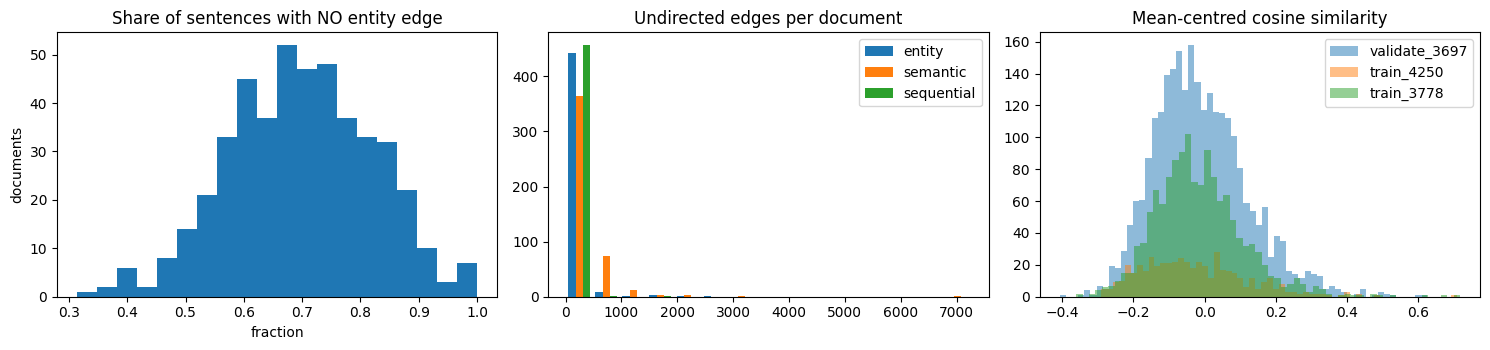

In [13]:
import matplotlib.pyplot as plt
Path(GRAPH_DIR, "figures").mkdir(exist_ok=True)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))

ax[0].hist(df.frac_nodes_no_entity_edge, bins=20)
ax[0].set_title("Share of sentences with NO entity edge"); ax[0].set_xlabel("fraction"); ax[0].set_ylabel("documents")

ax[1].hist([df.edges_entity, df.edges_semantic, df.edges_sequential], bins=15, label=RELATIONS)
ax[1].set_title("Undirected edges per document"); ax[1].legend()

sample = df.sample(min(3, len(df)), random_state=0)
for _, r in sample.iterrows():
    g = load_graph(Path(GRAPH_DIR, r.split, r.doc_id + ".pt"))
    E = g["x"][:, :g["emb_dim"]].numpy(); E = E - E.mean(0); E /= np.maximum(np.linalg.norm(E, axis=1, keepdims=True), 1e-8)
    S = E @ E.T; ax[2].hist(S[np.triu_indices_from(S, 1)], bins=60, alpha=0.5, label=r.doc_id)
ax[2].set_title("Mean-centred cosine similarity"); ax[2].legend()
plt.tight_layout(); plt.savefig(Path(GRAPH_DIR, "figures", "graph_diagnostics.png"), dpi=120); plt.show()

## 7. How to load a graph in the next step (GNN training)

In [14]:
def to_pyg(g):
    """dict -> torch_geometric Data (needs `pip install torch_geometric`)."""
    from torch_geometric.data import Data
    return Data(x=g["x"], edge_index=g["edge_index"], edge_type=g["edge_type"], edge_weight=g["edge_weight"],
                y=g["y"], y_soft=g["y_soft"], num_nodes=g["num_nodes"], doc_id=g["doc_id"])

# quick look at one saved graph
p = next(Path(GRAPH_DIR, "train").glob("*.pt"))
g = load_graph(p)
print(p.name, "| nodes:", g["num_nodes"], "| x:", tuple(g["x"].shape), "| edges:", g["edge_index"].shape[1])
print("keys:", list(g.keys()))
print("extra node features:", g["feat_names"])
try:
    print(to_pyg(g))
except ImportError:
    print("(torch_geometric not installed here; that is fine, install it in the training notebook)")

train_1007.pt | nodes: 42 | x: (42, 794) | edges: 408
keys: ['doc_id', 'split', 'filename', 'num_nodes', 'version', 'x', 'emb_dim', 'feat_names', 'edge_index', 'edge_type', 'edge_weight', 'relation_names', 'y', 'y_soft', 'oracle_idx', 'sentences', 'sections', 'sent_words', 'sent_entities', 'reference', 'stats']
extra node features: ['rel_position', 'log_words', 'log_n_entities', 'section_ARGUMENTS', 'section_FACTS', 'section_ISSUES', 'section_JUDGMENT', 'section_OTHER', 'section_PREAMBLE', 'section_REASONING', 'section_STATUTES', 'ent_CASE_NUMBER', 'ent_CITATION', 'ent_COURT', 'ent_DATE', 'ent_GPE', 'ent_JUDGE', 'ent_LAWYER', 'ent_ORG', 'ent_OTHER_PERSON', 'ent_PETITIONER', 'ent_PRECEDENT', 'ent_PROVISION', 'ent_RESPONDENT', 'ent_STATUTE', 'ent_WITNESS']
(torch_geometric not installed here; that is fine, install it in the training notebook)
